# Thermal consolidation around a point heat source

**Paper:** J. R. Booker and C. Savvidou, "Consolidation around a point heat source", *International Journal for Numerical and Analytical Methods in Geomechanics* 9(2):173–184, 1985. [doi:10.1002/nag.1610090206](https://doi.org/10.1002/nag.1610090206)

J. R. Booker and C. Savvidou: School of Civil and Mining Engineering, University of Sydney, Sydney 2006, New South Wales, Australia.

Input distributions and the $(r, t)$ grid: A. A. Chaudhry, J. Buchwald and T. Nagel (2021), as implemented in the UQTestFuns test function `SaturatedPointHeatSource` (D. Wicaksono; unreleased GitHub source, commit `82d5c8b`, not in the 0.7.0 PyPI release).

Notebook: Claude (Anthropic) for P. Constantine, 2026

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import heat_source_model as hm

SEED = 1985                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
names = list(hm.NAMES)
labels = [r'$K$', r'$C$', r'$\rho$', r'$E$', r'$\alpha_s$', r'$k_s$', r'$\nu$', r'$\phi$']
qois = ['dT', 'p', 'u_r']
qoi_labels = [r'$\Delta T$ (K)', r'$p$ (MPa)', r'$u_r$ (mm)']
plot_scale = np.array([1.0, 1e-6, 1e3])          # for axis labels only: Pa -> MPa, m -> mm

### Summary

Booker and Savvidou derived a closed-form solution for the temperature, excess pore pressure and displacement around a constant point heat source (for example a canister of heat-emitting nuclear waste) buried deep in a saturated poro-thermo-elastic soil or rock. We evaluate it, with exact gradients, at 1,000 random draws of the eight uncertain material properties of Chaudhry et al. (2021) and estimate active subspaces of the temperature change, excess pore pressure and radial displacement at $r = 6$ m, $t = 1$ year, and of all 300 field values on the $10 \times 10$ $(r, t)$ grid. The temperature change and the pore pressure each have a dominant one-dimensional active subspace (eigenvalue ratios $\lambda_1/\lambda_2 \approx 118$ and $52$), led by thermal conductivity and by permeability respectively, while the displacement needs two directions (ratios 9.3 and 21), mixing permeability and the thermal expansion of the solid.

### Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ normalized inputs with density $\rho$, the matrix $\mathbf{C} = \int \nabla f\, \nabla f^\top \rho\, d\mathbf{x} = \mathbf{W}\Lambda\mathbf{W}^\top$ measures how $f$ changes, on average, along each direction. If the first $n$ eigenvalues are much larger than the rest, $f$ changes mostly along the span of the first $n$ eigenvectors, and $f(\mathbf{x}) \approx g(\mathbf{W}_1^\top \mathbf{x})$ with the active variables $\mathbf{y} = \mathbf{W}_1^\top\mathbf{x}$. We estimate $\mathbf{C}$ from gradient samples, check the gaps between eigenvalues with bootstrap intervals, and look at sufficient summary plots of $f$ against $\mathbf{y}$. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

A point source of constant power $Q$ starts heating an infinite, saturated, isotropic poro-thermo-elastic medium at $t = 0$. Booker and Savvidou (1985, Eq. 23) give, at distance $r$ from the source and time $t$,

$$
\Delta T = \frac{Q}{4\pi K r}\, f^\kappa, \qquad
p = \frac{X}{1 - c/\kappa}\,\frac{Q}{4\pi K r}\,\bigl(f^\kappa - f^c\bigr), \qquad
u_r = \frac{Q}{4\pi K M}\Bigl[b' g^\kappa + \frac{X}{1 - c/\kappa}\bigl(g^\kappa - g^c\bigr)\Bigr],
$$

with, for a diffusivity $A \in \{\kappa, c\}$ and $\tau = At/r^2$,

$$
f^A = \operatorname{erfc}\!\Bigl(\frac{1}{2\sqrt{\tau}}\Bigr), \qquad
g^A = \tau + \Bigl(\tfrac12 - \tau\Bigr) f^A - \sqrt{\tau/\pi}\; e^{-1/(4\tau)},
$$

and derived constants $\kappa = K/(C\rho)$ (thermal diffusivity), $\lambda = E\nu/((1+\nu)(1-2\nu))$, $G = E/(2(1+\nu))$, $M = \lambda + 2G$, $c = k_s M/\mu_w$ (coefficient of consolidation), $\alpha_u = \phi\alpha_w + (1-\phi)\alpha_s$, $b' = (\lambda + 2G/3)\alpha_s$ and $X = \alpha_u M - b'$. Chaudhry et al. (2019) re-derived the solution: they confirmed these three fields and corrected only the stress expressions, which we do not use. The quotients have a removable singularity at $c = \kappa$; `heat_source_model.py` evaluates them as divided differences (by Gauss–Legendre quadrature of $\partial f^A/\partial A$ near $c = \kappa$), and computes exact gradients by the chain rule through $(Q/4\pi K, \kappa, c, M, b', X)$.

The 1985 paper has no parameter study. The eight inputs and their distributions are those of Chaudhry et al. (2021, Table 1) as listed in UQTestFuns (input set `Chaudhry2021`); they are independent. The held parameters are $Q = 3000$ W, $\alpha_w = 4\times10^{-4}$ 1/K and $\mu_w = 10^{-3}$ Pa s, and the grid is $r \in \{2, \dots, 30\}$ m by $t \in \{1\text{ d}, \dots, 5\text{ y}\}$ (UQTestFuns parameter set `Chaudhry2021`).

**Quantities of interest.** The scalar QoIs are $\Delta T$ (K), $p$ (Pa) and $u_r$ (m) at $r = 6$ m and $t = 1$ y (365 d), a point and time where the pore pressure is near its peak (see the reference values printed below). A sweep over all 100 grid cells follows. The table below is printed from the code (`hm.NAMES`, `hm.DISTRIBUTIONS`, `hm.mean_and_sd()`, `hm.bounds()`).

In [2]:
mean, sd = hm.mean_and_sd()
lo, hi = hm.bounds()
print(f"{'input':5s} {'units':9s} {'distribution':47s} {'mean':>10s} {'std':>10s}   {'support':21s} description")
for j, n in enumerate(names):
    print(f'{n:5s} {hm.UNITS[j]:9s} {hm.DISTRIBUTIONS[j]:47s} {mean[j]:10.4g} {sd[j]:10.4g}   '
          f'[{lo[j]:.3g}, {hi[j]:.3g}]'.ljust(24) + f' {hm.DESCRIPTIONS[j]}')
print(f'\nheld: Q = {hm.Q:g} W, a_w = {hm.A_W:g} 1/K, mu_w = {hm.MU_W:g} Pa s')
print('grid: r =', ', '.join(f'{r:g}' for r in hm.R_GRID), 'm; t =', ', '.join(hm.T_LABELS), '(1 y = 365 d)')
print(f'scalar quantities of interest at r = {hm.R_STAR:g} m, t = {hm.T_STAR / hm.DAY:g} d')
dT0, p0, u0 = hm.fields(hm.NOMINAL[None], [hm.R_STAR], hm.T_GRID)
print('at the reference point NOMINAL, p(6 m, t) in MPa:', ', '.join(f'{lab} {v:.2f}' for lab, v in zip(hm.T_LABELS, p0[0, 0] / 1e6)))

input units     distribution                                          mean        std   support               description
K     W/(m K)   TruncNormal(1.79, 0.34; [1.29, 2.45])                1.818     0.2725   [1.29, 2.45] total thermal conductivity
C     J/(kg K)  Normal(978, 68)                                        978         68   [-inf, inf] total specific heat capacity
rho   kg/m^3    TruncNormal(2480, 30; [2420, 2540])                   2480      26.39   [2.42e+03, 2.54e+03] total density
E     Pa        TruncNormal(1.28e+10, 3.7e+09; [5.5e+09, 2.01e+10])   1.28e+10  3.234e+09   [5.5e+09, 2.01e+10] Young's modulus (drained skeleton)
a_s   1/K       Uniform[3e-05, 7.5e-05]                           5.25e-05  1.299e-05   [3e-05, 7.5e-05] volumetric thermal expansion coefficient of the solid
k_s   m^2       TruncNormal(5.6e-20, 5.5e-20; [7.8e-21, 2.2e-19])  7.417e-20  4.185e-20   [7.8e-21, 2.2e-19] intrinsic permeability
nu    -         Triangular[0.2, 0.4], mode 0.3              

### Load the data

`generate_data.py` drew 1,000 independent samples (inverse-CDF transform of `numpy.random.default_rng(1985).random((1000, 8))`, i.e. simple Monte Carlo) and stored the physical inputs, the three scalar QoIs, their exact gradients with respect to the physical inputs, and the 300 field values.

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')                              # (M, 8) physical inputs
F = np.loadtxt('outputs.csv', delimiter=',')                             # (M, 3): dT (K), p (Pa), u_r (m) at (6 m, 1 y)
G = np.loadtxt('gradients.csv', delimiter=',').reshape(-1, 3, 8)         # exact gradients, physical inputs
Ffield = np.loadtxt('fields.csv', delimiter=',').reshape(-1, 3, 10, 10)  # (M, field, r, t)
M = len(X)
print(f'inputs {X.shape}, outputs {F.shape}, gradients {G.shape}, fields {Ffield.shape}')

inputs (1000, 8), outputs (1000, 3), gradients (1000, 3, 8), fields (1000, 3, 10, 10)


**Checks.** The next cell re-evaluates the model on the stored inputs, compares the exact gradients with central differences, checks $u_r$ against an independent radial integration of the volumetric strain ($M\,\nabla\cdot\mathbf{u} = p + b'\Delta T$), counts samples outside the physical domain, and reports how close the samples come to the removable singularity $c = \kappa$ and how many field values underflow to exactly zero (far from the source at early times the heat front has not arrived, so $\Delta T$ and $p$ are below $10^{-300}$).

In [4]:
Fm, Gm = hm.headline(X)
(dTm, pm, um), Gf = hm.fields_and_grads(X)        # all 300 field values and their exact gradients
print('model reproduces outputs.csv, gradients.csv, fields.csv exactly:',
      np.array_equal(Fm, F), np.array_equal(Gm, G), np.array_equal(np.stack([dTm, pm, um], axis=1), Ffield))
h = 1e-5 * sd
FD = np.stack([(hm.headline(X + h[j] * e)[0] - hm.headline(X - h[j] * e)[0]) / (2 * h[j])
               for j, e in enumerate(np.eye(8))], axis=2)
err = np.linalg.norm((FD - G) * sd, axis=2) / np.linalg.norm(G * sd, axis=2)
print('exact gradients vs central differences (step 1e-5 sd), max relative error (dT, p, u_r):',
      np.array2string(err.max(axis=0), precision=1))
print("u_r vs radial quadrature of (p + b' dT)/M at (6 m, 1 y), first sample: relative difference "
      f'{abs(hm.u_r_by_quadrature(X[0], hm.R_STAR, hm.T_STAR) / F[0, 2] - 1):.1e}')
K_, C_, rho_, E_, as_, ks_, nu_, phi_ = X.T
n_bad = np.sum((K_ <= 0) | (C_ <= 0) | (rho_ <= 0) | (E_ <= 0) | (as_ < 0) | (ks_ <= 0)
               | (nu_ <= -1) | (nu_ >= 0.5) | (phi_ < 0) | (phi_ > 1))
n_out = np.sum(np.any((X < lo) | (X > hi), axis=1))
print(f'samples outside the physical domain: {n_bad}; outside the stated supports: {n_out}; '
      f'smallest C (unbounded normal): {C_.min():.1f} J/(kg K)')
d = hm.derived(X)
ratio = d['c'] / d['kappa']
print(f'c/kappa in [{ratio.min():.3f}, {ratio.max():.3f}]; c > kappa at {np.mean(ratio > 1):.3f} of the samples; '
      f'|1 - c/kappa| < 0.1 at {np.sum(np.abs(1 - ratio) < 0.1)} samples')
zero = (Ffield == 0).sum(axis=0)                  # (field, r, t)
print('field values that underflow to exactly 0 (of', M * 100, 'per field): dT', zero[0].sum(), ', p', zero[1].sum(),
      ', u_r', zero[2].sum(), '; grid cells with at least one zero:', [int((zero[k] > 0).sum()) for k in range(3)])
for k, q in enumerate(qois):
    print(f'{q} at (6 m, 1 y): range [{F[:, k].min():.4g}, {F[:, k].max():.4g}], mean {F[:, k].mean():.4g}, '
          f'max/min {F[:, k].max() / F[:, k].min():.2f}')

model reproduces outputs.csv, gradients.csv, fields.csv exactly: True True True
exact gradients vs central differences (step 1e-5 sd), max relative error (dT, p, u_r): [1.0e-09 3.1e-09 6.9e-10]
u_r vs radial quadrature of (p + b' dT)/M at (6 m, 1 y), first sample: relative difference 2.0e-15
samples outside the physical domain: 0; outside the stated supports: 0; smallest C (unbounded normal): 769.4 J/(kg K)
c/kappa in [0.083, 7.029]; c > kappa at 0.694 of the samples; |1 - c/kappa| < 0.1 at 72 samples
field values that underflow to exactly 0 (of 100000 per field): dT 3993 , p 2941 , u_r 0 ; grid cells with at least one zero: [6, 6, 0]
dT at (6 m, 1 y): range [7.016, 10.26], mean 8.394, max/min 1.46
p at (6 m, 1 y): range [1.748e+06, 1.727e+07], mean 5.312e+06, max/min 9.88
u_r at (6 m, 1 y): range [0.000845, 0.004376], mean 0.001994, max/min 5.18


### Estimate the active subspaces

The model is cheap and smooth and its gradients are exact, so we use the gradient (outer product) estimator `estimator='as'` with 500 bootstrap replicates. The inputs are not all Gaussian (truncated normals, a normal, a uniform and a triangular), so we scale **every** input the same way, by its own mean and standard deviation: `ac.Gaussian(mean, sd**2)` serves only as the affine map $z_j = (x_j - \bar{x}_j)/s_j$; the expectation is taken over the true input distribution through the samples. Physical inputs and physical gradients are passed to the library, which applies this map once. A second scaling, each input through its own CDF to a standard normal, is shown further below as a check.

In [5]:
space = ac.Gaussian(mean, sd**2, names=names)       # affine map (x - mean)/sd for all eight inputs
subs = []
for k, q in enumerate(qois):
    sub = ac.active_subspace(space=space, X=X, f=F[:, k], grads=G[:, k], estimator='as', nboot=500, rng=SEED)
    sub = ac.orient(sub, by='mean_gradient', grads=G[:, k])     # sign: the QoI increases along w1
    subs.append(sub)
    lam, B = sub.eigenvalues, sub.bootstrap_eigenvalues
    ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
    with np.errstate(divide='ignore', invalid='ignore'):
        r = lam[:-1] / lam[1:]
        br = np.percentile(B[:, :2] / B[:, 1:3], [2.5, 97.5], axis=0)
    print(f'{q}: eigenvalues / lambda_1 =', np.array2string(lam / lam[0], precision=3))
    print(f'    gap rule n = {k_hat}; lambda_k/lambda_k+1, k = 1..4:', np.array2string(r[:4], precision=2),
          f'; 95% bootstrap ranges: lambda_1/lambda_2 [{br[0, 0]:.1f}, {br[1, 0]:.1f}], '
          f'lambda_2/lambda_3 [{br[0, 1]:.2f}, {br[1, 1]:.2f}]')
    print(f'    share of the trace: lambda_1 {lam[0] / lam.sum():.4f}, lambda_1 + lambda_2 {lam[:2].sum() / lam.sum():.4f}')

dT: eigenvalues / lambda_1 = [1.000e+00 8.506e-03 3.761e-05 0.000e+00 0.000e+00 0.000e+00 0.000e+00
 0.000e+00]
    gap rule n = 1; lambda_k/lambda_k+1, k = 1..4: [117.57 226.17    inf    nan] ; 95% bootstrap ranges: lambda_1/lambda_2 [105.9, 130.5], lambda_2/lambda_3 [201.23, 257.35]
    share of the trace: lambda_1 0.9915, lambda_1 + lambda_2 1.0000


p: eigenvalues / lambda_1 = [1.000e+00 1.935e-02 4.701e-03 7.652e-04 3.238e-04 7.734e-05 4.797e-06
 2.351e-07]
    gap rule n = 1; lambda_k/lambda_k+1, k = 1..4: [51.67  4.12  6.14  2.36] ; 95% bootstrap ranges: lambda_1/lambda_2 [43.1, 62.3], lambda_2/lambda_3 [3.46, 4.85]
    share of the trace: lambda_1 0.9754, lambda_1 + lambda_2 0.9943


u_r: eigenvalues / lambda_1 = [1.000e+00 1.072e-01 5.023e-03 2.349e-03 4.603e-04 1.306e-04 2.901e-06
 2.635e-07]
    gap rule n = 1; lambda_k/lambda_k+1, k = 1..4: [ 9.33 21.35  2.14  5.1 ] ; 95% bootstrap ranges: lambda_1/lambda_2 [8.4, 10.3], lambda_2/lambda_3 [18.69, 24.16]
    share of the trace: lambda_1 0.8967, lambda_1 + lambda_2 0.9929


### Results

**Eigenvalues.** The figure shows the eigenvalues of the three quantities with 95 % bootstrap bands (zero eigenvalues cannot be drawn on the log axis).

dT: lambda_4..lambda_8 = [0. 0. 0. 0. 0.]


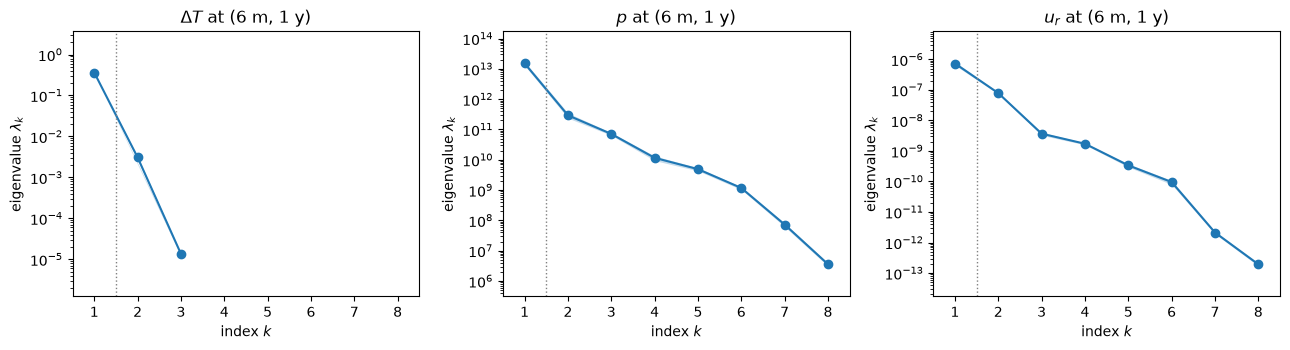

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, sub, ql in zip(axes, subs, qoi_labels):
    ac.plotting.plot_eigenvalues(sub, ax=ax)
    ax.set_title(ql.split(' (')[0] + ' at (6 m, 1 y)')
fig.tight_layout()
plt.close(fig)
print('dT: lambda_4..lambda_8 =', np.array2string(subs[0].eigenvalues[3:], precision=1))
fig

For $\Delta T$, $\lambda_1/\lambda_2 = 117.6$ (95 % bootstrap range 105.9 to 130.5) and $\lambda_1$ carries 0.9915 of the trace; $\lambda_4, \dots, \lambda_8$ are exactly zero because $\Delta T$ depends only on $K$, $C$ and $\rho$. For $p$, $\lambda_1/\lambda_2 = 51.7$ (43.1 to 62.3) with $\lambda_1$ carrying 0.9754 of the trace. For $u_r$ the first gap is smaller, $\lambda_1/\lambda_2 = 9.3$ (8.4 to 10.3), and the second gap is larger, $\lambda_2/\lambda_3 = 21.4$ (18.7 to 24.2): the first two eigenvalues carry 0.9929 of the trace. The gap rule picks $n = 1$ for all three.

dT: bootstrap mean subspace distance, k = 1..4: [0.0023 0.0018 0.     0.    ]
p: bootstrap mean subspace distance, k = 1..4: [0.0086 0.0346 0.0284 0.0444]
u_r: bootstrap mean subspace distance, k = 1..4: [0.015  0.0095 0.0412 0.0239]


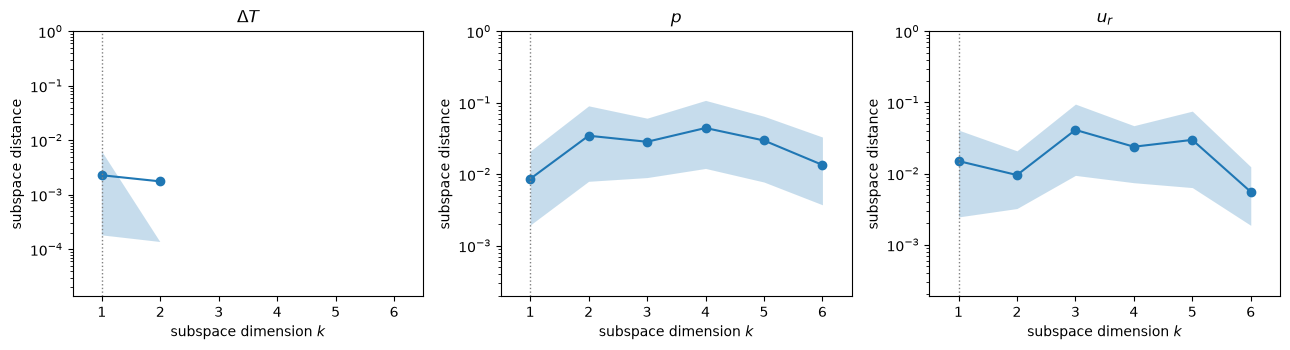

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, sub, ql in zip(axes, subs, qoi_labels):
    ac.plotting.plot_subspace_errors(sub, ax=ax, k_max=6)
    ax.set_title(ql.split(' (')[0])
fig.tight_layout()
plt.close(fig)
for q, sub in zip(qois, subs):
    print(f'{q}: bootstrap mean subspace distance, k = 1..4:', np.array2string(sub.bootstrap_distances.mean(axis=0)[:4], precision=4))
fig

The bootstrap mean distance between the estimated and resampled one-dimensional subspaces is 0.0023 for $\Delta T$, 0.0086 for $p$ and 0.0150 for $u_r$; for the two-dimensional subspace of $u_r$ it is 0.0095. All three leading subspaces are well determined by 1,000 gradients.

dT   w1: K -0.777, C -0.622, rho -0.094, E -0.000, a_s -0.000, k_s -0.000, nu -0.000, phi -0.000
     w2: K -0.629, C +0.764, rho +0.145, E -0.000, a_s -0.000, k_s -0.000, nu -0.000, phi -0.000
p    w1: K -0.119, C -0.044, rho -0.007, E +0.188, a_s +0.056, k_s -0.960, nu +0.041, phi +0.146
     w2: K -0.226, C -0.093, rho -0.014, E +0.880, a_s +0.139, k_s +0.257, nu +0.066, phi +0.275
u_r  w1: K -0.211, C -0.048, rho -0.007, E -0.138, a_s +0.306, k_s -0.912, nu -0.001, phi +0.098
     w2: K -0.391, C -0.097, rho -0.015, E -0.250, a_s +0.768, k_s +0.401, nu +0.131, phi +0.090
dT: w1(rho)/w1(C) = 0.1507; ratio of coefficients of variation (sd/mean) of rho and C = 0.1530


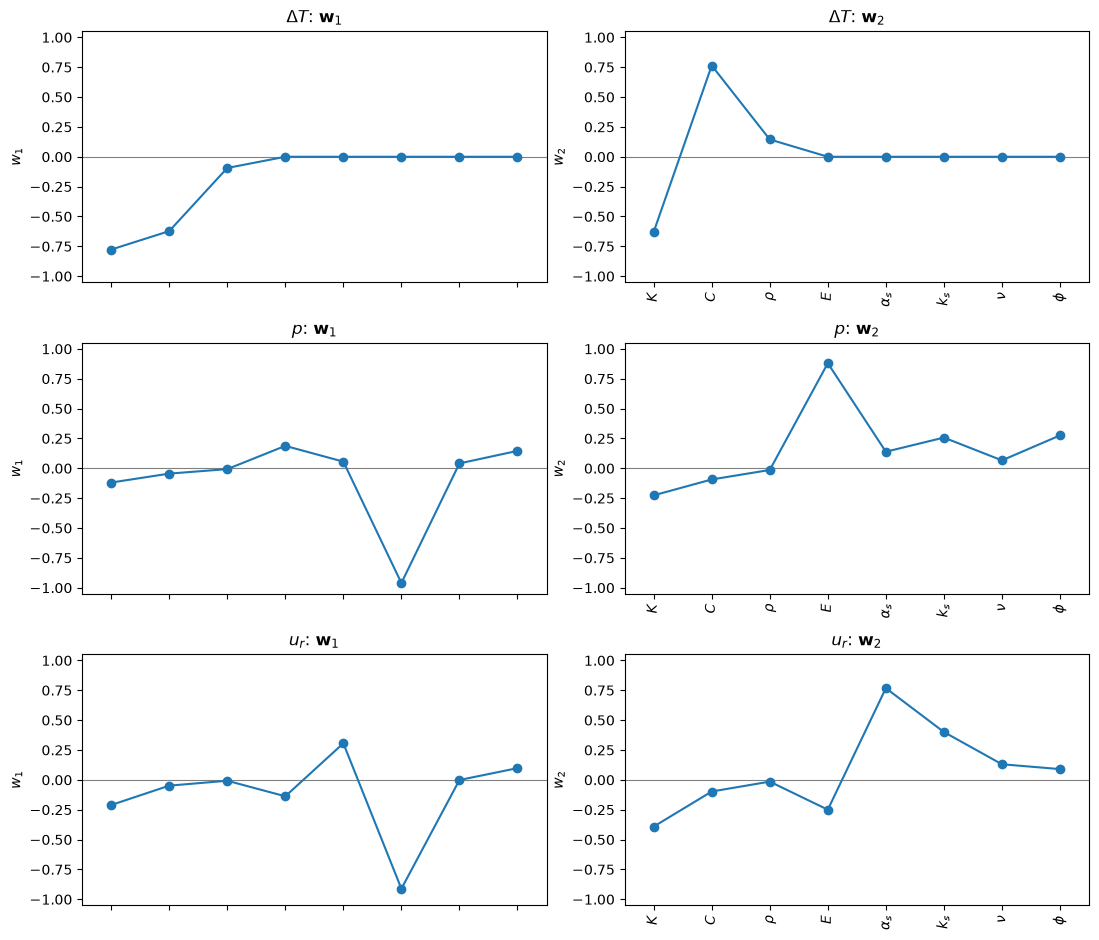

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(11, 9.5))
for k, (sub, ql) in enumerate(zip(subs, qoi_labels)):
    ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, ax=list(axes[k]))
    axes[k, 0].set_title(f'{ql.split(" (")[0]}: $\\mathbf{{w}}_1$')
    axes[k, 1].set_title(f'{ql.split(" (")[0]}: $\\mathbf{{w}}_2$')
    W = sub.eigenvectors
    print(f'{qois[k]:4s} w1:', ', '.join(f'{n} {v:+.3f}' for n, v in zip(names, W[:, 0])))
    print(f'{"":4s} w2:', ', '.join(f'{n} {v:+.3f}' for n, v in zip(names, W[:, 1])))
W0 = subs[0].eigenvectors[:, 0]
print(f'dT: w1(rho)/w1(C) = {W0[2] / W0[1]:.4f}; ratio of coefficients of variation '
      f'(sd/mean) of rho and C = {(sd[2] / mean[2]) / (sd[1] / mean[1]):.4f}')
fig.tight_layout()
plt.close(fig)
fig

**$\Delta T$:** $\mathbf{w}_1$ weights $K$ ($-0.777$), $C$ ($-0.622$) and $\rho$ ($-0.094$): more conduction spreads the heat and lowers the temperature at 6 m, and more heat capacity slows the front. Since $C$ and $\rho$ enter only through their product, their weights are in the ratio of their coefficients of variation (0.1507 against 0.1530). **$p$:** $\mathbf{w}_1$ is dominated by the intrinsic permeability ($k_s$: $-0.960$; then $E$ $+0.188$, $\phi$ $+0.146$, $K$ $-0.119$): permeable rock drains the thermally generated pore pressure. **$u_r$:** $\mathbf{w}_1$ is again led by $k_s$ ($-0.912$), with the solid's expansion coefficient $\alpha_s$ ($+0.306$) and $K$ ($-0.211$); $\mathbf{w}_2$ is led by $\alpha_s$ ($+0.768$), $k_s$ ($+0.401$) and $K$ ($-0.391$).

dT: y1 in [-2.65, 2.61]; corr(f, y1) = 0.9944; Spearman corr(f, y1) = 0.9981
p: y1 in [-3.43, 1.98]; corr(f, y1) = 0.8809; Spearman corr(f, y1) = 0.9802
u_r: y1 in [-3.50, 2.30]; corr(f, y1) = 0.8127; Spearman corr(f, y1) = 0.8207


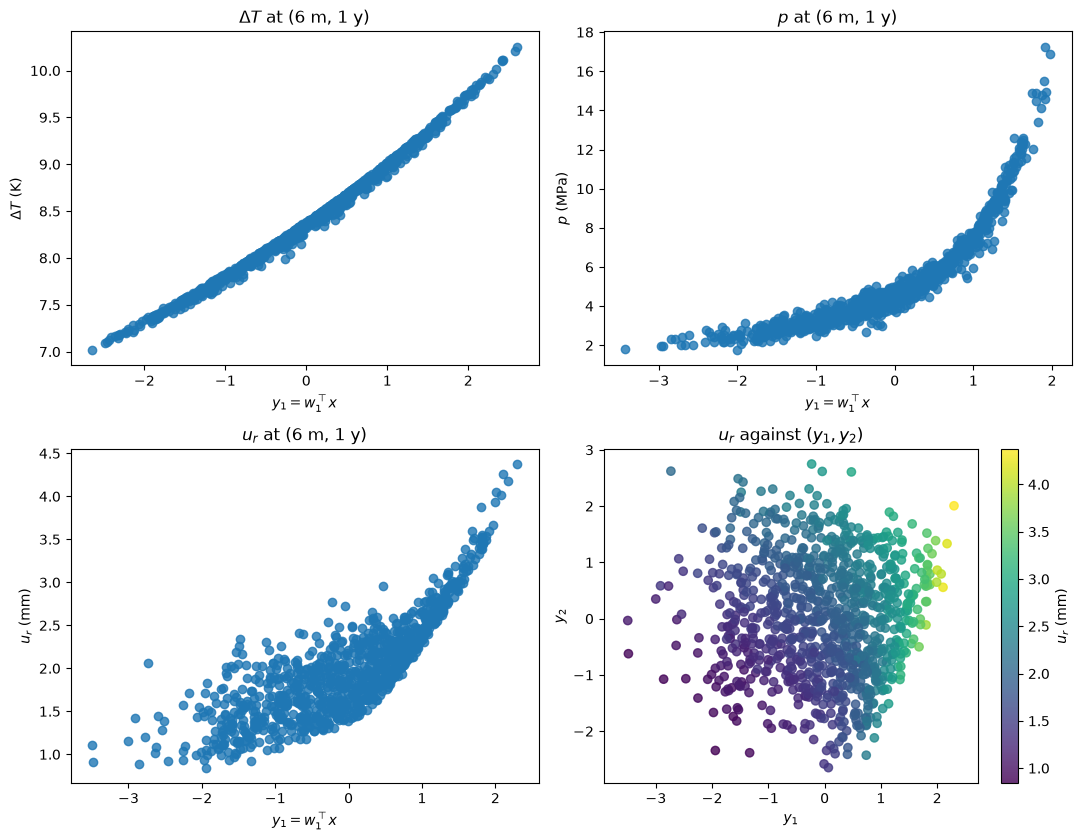

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
for ax, k in zip([axes[0, 0], axes[0, 1], axes[1, 0]], range(3)):
    ac.plotting.plot_sufficient_summary(subs[k], X=X, f=F[:, k] * plot_scale[k], dims=1, qoi_label=qoi_labels[k], ax=ax)
    ax.set_title(qoi_labels[k].split(' (')[0] + ' at (6 m, 1 y)')
ac.plotting.plot_sufficient_summary(subs[2], X=X, f=F[:, 2] * plot_scale[2], dims=2, qoi_label=qoi_labels[2], ax=axes[1, 1])
axes[1, 1].set_title(r'$u_r$ against $(y_1, y_2)$')
fig.tight_layout()
plt.close(fig)
Xn = space.to_normalized(X)
for k, q in enumerate(qois):
    y = Xn @ subs[k].eigenvectors[:, :2]
    print(f'{q}: y1 in [{y[:, 0].min():.2f}, {y[:, 0].max():.2f}]; corr(f, y1) = {np.corrcoef(F[:, k], y[:, 0])[0, 1]:.4f}; '
          f'Spearman corr(f, y1) = {np.corrcoef(np.argsort(np.argsort(F[:, k])), np.argsort(np.argsort(y[:, 0])))[0, 1]:.4f}')
fig

The sufficient summary plot of $\Delta T$ is a thin, slightly convex curve in $y_1$ (Pearson correlation 0.9944, Spearman 0.9981). The pore pressure is a monotone, strongly convex function of $y_1$ with a narrow band of scatter (Spearman 0.9802; the Pearson value 0.8809 is lowered by the curvature). The displacement shows wide scatter against $y_1$ alone (Spearman 0.8207); against $(y_1, y_2)$ the colours change smoothly in both directions, consistent with a two-dimensional active subspace.

#### Surrogates on the active variables

We fit polynomials in the active variables and report the leave-one-out $R^2$: cubics in $y_1$ for the three quantities, and a quadratic and a cubic in $(y_1, y_2)$ for $u_r$, whose active subspace is two-dimensional.

dT   LOO R^2: line in y1 0.9888, cubic in y1 0.9969, quadratic in (y1, y2) 0.9996, cubic in (y1, y2) 1.0000
p    LOO R^2: line in y1 0.7743, cubic in y1 0.9675, quadratic in (y1, y2) 0.9457, cubic in (y1, y2) 0.9783
u_r  LOO R^2: line in y1 0.6587, cubic in y1 0.7848, quadratic in (y1, y2) 0.9576, cubic in (y1, y2) 0.9805


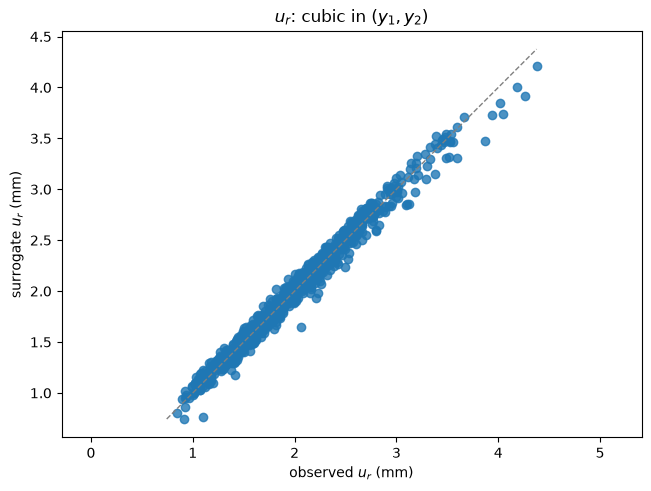

In [10]:
loo = {}
for k, q in enumerate(qois):
    for deg in (1, 3):
        loo[(q, 1, deg)] = ac.fit_surrogate(X=X, f=F[:, k], subspace=ac.with_dimension(subs[k], 1), kind='poly', degree=deg).loo_r_squared
    for deg in (2, 3):
        loo[(q, 2, deg)] = ac.fit_surrogate(X=X, f=F[:, k], subspace=ac.with_dimension(subs[k], 2), kind='poly', degree=deg).loo_r_squared
for q in qois:
    print(f'{q:4s} LOO R^2: line in y1 {loo[(q, 1, 1)]:.4f}, cubic in y1 {loo[(q, 1, 3)]:.4f}, '
          f'quadratic in (y1, y2) {loo[(q, 2, 2)]:.4f}, cubic in (y1, y2) {loo[(q, 2, 3)]:.4f}')
sur_u = ac.fit_surrogate(X=X, f=F[:, 2] * plot_scale[2], subspace=ac.with_dimension(subs[2], 2), kind='poly', degree=3)
fig, ax = ac.plotting.plot_surrogate_fit(sur_u, X=X, f=F[:, 2] * plot_scale[2], qoi_label=qoi_labels[2])
ax.set_title(r'$u_r$: cubic in $(y_1, y_2)$')
plt.close(fig)
fig

A cubic in $y_1$ gives a leave-one-out $R^2$ of 0.9969 for $\Delta T$ and 0.9675 for $p$, but only 0.7848 for $u_r$; a quadratic in $(y_1, y_2)$ raises $u_r$ to 0.9576 and a cubic in $(y_1, y_2)$ to 0.9805. For $\Delta T$ the quadratic in $(y_1, y_2)$ reaches 0.9996.

#### Check: a different scaling of the inputs

The affine scaling treats the bounded inputs by their standard deviations. As a check we map each input through its own CDF to a standard normal, $z_j = \Phi^{-1}(F_j(x_j))$, multiply the physical gradients by $dx_j/dz_j$, and repeat the estimate. The table printed below compares the eigenvalue ratios and the leading eigenvector ($|\mathbf{w}_1^{(t)} \cdot \mathbf{w}_1|$, with both vectors written over the eight inputs).

In [11]:
Xt = hm.to_gaussian(X)
J = hm.dx_dz(X)
space_t = ac.Gaussian.reference(8, names=[f'z_{n}' for n in names])
for k, q in enumerate(qois):
    st = ac.active_subspace(space=space_t, X=Xt, f=F[:, k], grads=G[:, k] * J, estimator='as', nboot=500, rng=SEED)
    st = ac.orient(st, by='mean_gradient', grads=G[:, k] * J)
    lt, wt = st.eigenvalues, st.eigenvectors
    print(f'{q:4s} transformed: lambda_1/lambda_2 = {lt[0] / lt[1]:.1f}, lambda_2/lambda_3 = {lt[1] / lt[2]:.2f}; '
          f'|w1(t).w1| = {abs(wt[:, 0] @ subs[k].eigenvectors[:, 0]):.4f}; '
          'w1(t): ' + ', '.join(f'{n} {v:+.3f}' for n, v in zip(names, wt[:, 0]) if abs(v) >= 0.1))

dT   transformed: lambda_1/lambda_2 = 38.1, lambda_2/lambda_3 = 95.04; |w1(t).w1| = 0.9998; w1(t): K -0.788, C -0.608


p    transformed: lambda_1/lambda_2 = 17.0, lambda_2/lambda_3 = 8.41; |w1(t).w1| = 0.9892; w1(t): K -0.182, E +0.272, k_s -0.910, phi +0.226


u_r  transformed: lambda_1/lambda_2 = 10.9, lambda_2/lambda_3 = 5.15; |w1(t).w1| = 0.9122; w1(t): K -0.358, E -0.240, a_s +0.585, k_s -0.665, phi +0.149


The conclusions survive the change of scaling, with smaller first gaps: $\lambda_1/\lambda_2 = 38.1$ for $\Delta T$, 17.0 for $p$ and 10.9 for $u_r$, and $|\mathbf{w}_1^{(t)}\cdot\mathbf{w}_1| = 0.9998$, 0.9892 and 0.9122. Under this scaling $\alpha_s$ ($+0.585$) comes close to $k_s$ ($-0.665$) in $\mathbf{w}_1$ of $u_r$, which is the same two-dimensional structure seen above.

#### Sweep over the $(r, t)$ grid

For each of the 300 field values we estimate $\mathbf{C}$ from the exact gradients (same affine scaling, all 1,000 samples) and map $\log_{10}(\lambda_1/\lambda_2)$ and the input with the largest $|w_{1j}|$. Cells where the median of $|f|$ over the samples is below $10^{-6}$ of its largest value over the grid (the heat front has not arrived) are marked "–" and excluded.

dT    71 cells analysed (29 negligible): lambda_1/lambda_2 median 145.8, min 11.70, > 10 in 1.00 of cells; cells with lambda_1/lambda_2 < 10 and lambda_2/lambda_3 > 10: 0; largest |w1j|: C 17, K 54
p     77 cells analysed (23 negligible): lambda_1/lambda_2 median 20.0, min 1.58, > 10 in 0.58 of cells; cells with lambda_1/lambda_2 < 10 and lambda_2/lambda_3 > 10: 29; largest |w1j|: k_s 77
u_r  100 cells analysed (0 negligible): lambda_1/lambda_2 median 26.4, min 3.10, > 10 in 0.73 of cells; cells with lambda_1/lambda_2 < 10 and lambda_2/lambda_3 > 10: 27; largest |w1j|: a_s 49, k_s 51
check: the sweep at (6 m, 1 y) gives lambda_1/lambda_2 = [117.57  51.67   9.33]
dT: largest lambda_1/lambda_2 = 2.87e+05 at r = 2 m, t = 5y
p: radius of the smallest lambda_1/lambda_2 at each time: 1d 2 m (32.20), 7d 2 m (3.09), 30d 4 m (2.81), 90d 6 m (1.90), 180d 8 m (1.66), 1y 10 m (1.83), 2y 15 m (1.58), 3y 20 m (1.70), 4y 20 m (1.83), 5y 25 m (1.61)
u_r: input with the largest |w1j| (rows t; columns r

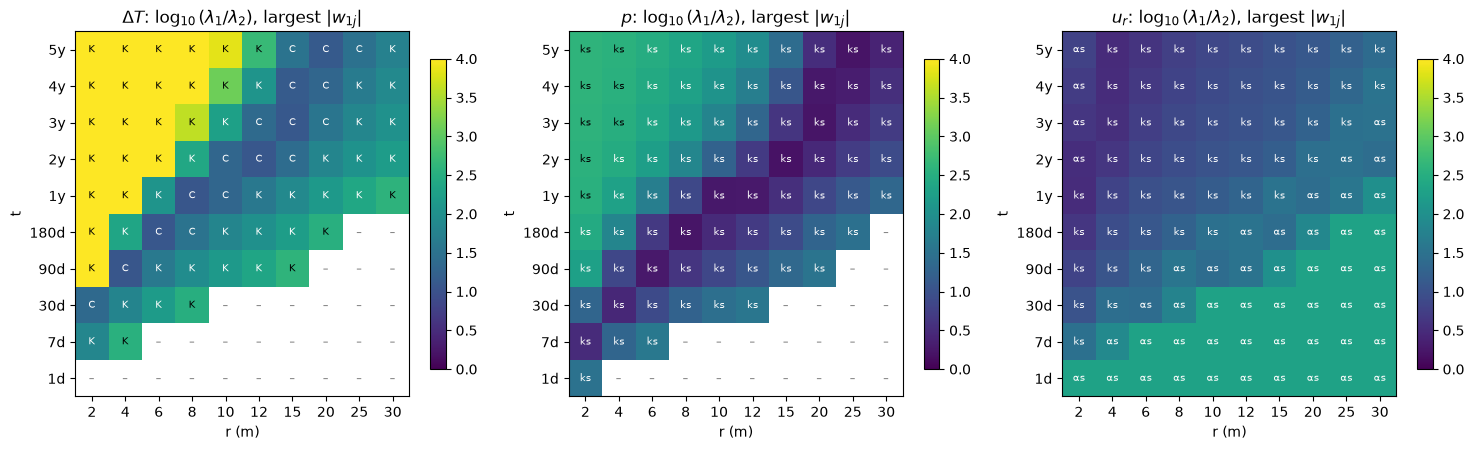

In [12]:
Gn = [space.grads_to_normalized(Gf[k].reshape(-1, 8)).reshape(M, 10, 10, 8) for k in range(3)]
vals = [dTm, pm, um]
ratio12 = np.full((3, 10, 10), np.nan)
ratio23 = np.full((3, 10, 10), np.nan)
lead = np.empty((3, 10, 10), dtype=object)
negligible = np.zeros((3, 10, 10), dtype=bool)
for k in range(3):
    med = np.median(np.abs(vals[k]), axis=0)
    negligible[k] = med < 1e-6 * med.max()
    for i in range(10):
        for j in range(10):
            g = Gn[k][:, i, j, :]
            lam, W = np.linalg.eigh(g.T @ g / M)
            lam, W = lam[::-1], W[:, ::-1]
            if lam[0] == 0:
                continue
            with np.errstate(divide='ignore'):
                ratio12[k, i, j], ratio23[k, i, j] = lam[0] / lam[1], lam[1] / lam[2]
            lead[k, i, j] = names[np.argmax(np.abs(W[:, 0]))]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
short = {'K': 'K', 'C': 'C', 'rho': 'ρ', 'E': 'E', 'a_s': 'αs', 'k_s': 'ks', 'nu': 'ν', 'phi': 'φ'}
for k, ax in enumerate(axes):
    val = np.log10(np.where(negligible[k], np.nan, ratio12[k]))
    im = ax.imshow(val.T, origin='lower', cmap='viridis', vmin=0, vmax=4, aspect='auto')
    for i in range(10):
        for j in range(10):
            if negligible[k, i, j]:
                ax.text(i, j, '–', ha='center', va='center', fontsize=8, color='0.5')
            else:
                ax.text(i, j, short[lead[k, i, j]], ha='center', va='center', fontsize=7,
                        color='white' if val[i, j] < 2.5 else 'black')
    ax.set_xticks(range(10), [f'{r:g}' for r in hm.R_GRID])
    ax.set_yticks(range(10), hm.T_LABELS)
    ax.set_xlabel('r (m)')
    ax.set_ylabel('t')
    ax.set_title(qoi_labels[k].split(' (')[0] + r': $\log_{10}(\lambda_1/\lambda_2)$, largest $|w_{1j}|$')
    fig.colorbar(im, ax=ax, shrink=0.85)
fig.tight_layout()
plt.close(fig)
for k, q in enumerate(qois):
    ok = ~negligible[k]
    r12, r23 = ratio12[k][ok], ratio23[k][ok]
    leads, counts = np.unique(lead[k][ok].astype(str), return_counts=True)
    print(f'{q:4s} {ok.sum():3d} cells analysed ({negligible[k].sum()} negligible): lambda_1/lambda_2 median {np.median(r12):.1f}, '
          f'min {r12.min():.2f}, > 10 in {np.mean(r12 > 10):.2f} of cells; cells with lambda_1/lambda_2 < 10 and lambda_2/lambda_3 > 10: '
          f'{np.sum((r12 < 10) & (r23 > 10))}; largest |w1j|: ' + ', '.join(f'{a} {b}' for a, b in zip(leads, counts)))
i6, j1 = list(hm.R_GRID).index(hm.R_STAR), list(hm.T_DAYS).index(hm.T_STAR / hm.DAY)
print('check: the sweep at (6 m, 1 y) gives lambda_1/lambda_2 =', np.array2string(ratio12[:, i6, j1], precision=2))
r_dT = np.where(negligible[0], np.nan, ratio12[0])
i_mx, j_mx = np.unravel_index(np.nanargmax(r_dT), r_dT.shape)
print(f'dT: largest lambda_1/lambda_2 = {r_dT[i_mx, j_mx]:.3g} at r = {hm.R_GRID[i_mx]:g} m, t = {hm.T_LABELS[j_mx]}')
r_p = np.where(negligible[1], np.nan, ratio12[1])
print('p: radius of the smallest lambda_1/lambda_2 at each time: ' + ', '.join(
    f'{hm.T_LABELS[j]} {hm.R_GRID[np.nanargmin(r_p[:, j])]:g} m ({np.nanmin(r_p[:, j]):.2f})'
    for j in range(10) if np.any(np.isfinite(r_p[:, j]))))
print('u_r: input with the largest |w1j| (rows t; columns r =', ' '.join(f'{r:g}' for r in hm.R_GRID), 'm)')
for j in range(10):
    print(f'  {hm.T_LABELS[j]:>4s} ' + ' '.join(f'{lead[2, i, j]:>4s}' for i in range(10)))
fig

Every analysed $\Delta T$ cell has $\lambda_1/\lambda_2 > 10$ (median 145.8, minimum 11.7), led by $K$ (54 cells) or $C$ (17 cells); near the source at late times $\Delta T \to Q/(4\pi K r)$ depends on $K$ alone, and the largest ratio is $2.87\times10^5$ at (2 m, 5 y) (the colour bar is clipped at $10^4$). For $p$ the median ratio is 20.0, but the ratio drops below 2 along a band in $(r, t)$ that moves outward with time: the smallest ratio at each time lies at 6 m at 90 d (1.90), 8 m at 180 d (1.66), 10 m at 1 y (1.83), 15 m at 2 y (1.58, the grid minimum), 20 m at 3 and 4 y (1.70, 1.83) and 25 m at 5 y (1.61). 29 of 77 cells have $\lambda_1/\lambda_2 < 10$ with $\lambda_2/\lambda_3 > 10$, i.e. a two-dimensional subspace. $k_s$ has the largest weight in every analysed $p$ cell. For $u_r$ (median 26.4, minimum 3.10, 27 two-dimensional cells) $\alpha_s$ has the largest weight in 49 cells and $k_s$ in the other 51. The printed map shows $\alpha_s$ leading ahead of a front that moves outward with time (all ten radii at 1 d, $r \ge 4$ m at 7 d, $r \ge 6$ m at 30 d, $r \ge 8$ m at 90 d, $r \ge 12$ m at 180 d, $r \ge 20$ m at 1 y, $r \ge 25$ m at 2 y, $r = 30$ m at 3 y, no radius beyond 2 m at 4–5 y) and at $r = 2$ m from 2 y on; $k_s$ leads behind the front, where consolidation controls the displacement. At the headline point (6 m, 1 y) $p$ has a larger gap (51.7) than its grid median, while $u_r$ (9.3) has a smaller one.

### Comparison with the paper

The 1985 paper reports no parameter study, so there are no active-subspace results to compare. We compare (i) the global sensitivity ranking of Chaudhry et al. (2021), as transcribed in the UQTestFuns documentation (the page for `SaturatedPointHeatSource` in the same unreleased source tree) from their Fig. 16 (rank of the maximum first-order Sobol' index over the grid; we have not read the 2021 paper), and (ii) the two functions $f$ and $g$ plotted in Fig. 1 of the 1985 paper.

**(i) First-order Sobol' indices.** Monte Carlo with $N = 50{,}000$ independent samples and a given-data estimator (equal-probability bins of $x_j$, 50 bins, bias-corrected), maximum over the analysed grid cells, with $\pm 2$ standard errors from five batches of 10,000. This is a different sample from the 1,000 used above (seed `[SEED, 1]`).

In [13]:
N_sobol, n_bins, n_batch = 50000, 50, 5
rng_s = np.random.default_rng([SEED, 1])
U = rng_s.random((N_sobol, 8))
Xs = hm.ppf(U)
Fs = np.empty((3, N_sobol, 100))
for i in range(0, N_sobol, 5000):
    out = hm.fields(Xs[i:i + 5000])
    for k in range(3):
        Fs[k, i:i + 5000] = out[k].reshape(-1, 100)

def first_order(Fk, Uk):
    # S_j = Var(E[f | x_j]) / Var(f): equal-probability bins of x_j, bias-corrected by (n_bins - 1)/N
    N = len(Fk)
    V = Fk.var(axis=0)
    kap = (n_bins - 1) / N
    S = np.full((8, Fk.shape[1]), np.nan)
    for j in range(8):
        mb = Fk[np.argsort(Uk[:, j])].reshape(n_bins, N // n_bins, -1).mean(axis=1)
        vb = ((mb - Fk.mean(axis=0))**2).mean(axis=0)
        with np.errstate(divide='ignore', invalid='ignore'):
            S[j] = np.where(V > 0, (vb / V - kap) / (1 - kap), np.nan)
    return S

smax = np.zeros((3, 8))
smax_batch = np.zeros((n_batch, 3, 8))
nb = N_sobol // n_batch
for k in range(3):
    keep = ~negligible[k].ravel()                    # the same grid cells as in the sweep above
    smax[k] = np.nanmax(first_order(Fs[k][:, keep], U), axis=1)
    for b in range(n_batch):
        smax_batch[b, k] = np.nanmax(first_order(Fs[k, b * nb:(b + 1) * nb][:, keep], U[b * nb:(b + 1) * nb]), axis=1)
half = 2 * smax_batch.std(axis=0, ddof=1) / np.sqrt(n_batch)   # 2 standard errors of the full-sample estimate
uqtf_rank = {'dT': [1, 2, 3, None, None, None, None, None], 'p': [7, 6, 8, 2, 3, 1, 5, 4], 'u_r': [1, 5, 8, 7, 3, 2, 6, 4]}
for k, q in enumerate(qois):
    order = np.argsort(-smax[k])
    rank = np.empty(8, int)
    rank[order] = np.arange(1, 9)
    print(f'{q}: max over the {int((~negligible[k]).sum())} analysed grid cells of the first-order Sobol\' index (N = {N_sobol}; +- 2 batch standard errors)')
    print('   ' + ', '.join(f'{names[j]} {smax[k, j]:.3f}+-{half[k, j]:.3f} (rank {rank[j]}, UQTestFuns '
                            f'{uqtf_rank[q][j] if uqtf_rank[q][j] else "N/A"})' for j in order))

dT: max over the 71 analysed grid cells of the first-order Sobol' index (N = 50000; +- 2 batch standard errors)
   K 0.998+-0.000 (rank 1, UQTestFuns 1), C 0.939+-0.001 (rank 2, UQTestFuns 2), rho 0.022+-0.003 (rank 3, UQTestFuns 3), phi 0.001+-0.001 (rank 4, UQTestFuns N/A), E 0.000+-0.000 (rank 5, UQTestFuns N/A), nu 0.000+-0.001 (rank 6, UQTestFuns N/A), k_s 0.000+-0.001 (rank 7, UQTestFuns N/A), a_s 0.000+-0.001 (rank 8, UQTestFuns N/A)
p: max over the 77 analysed grid cells of the first-order Sobol' index (N = 50000; +- 2 batch standard errors)
   k_s 0.888+-0.001 (rank 1, UQTestFuns 1), E 0.575+-0.005 (rank 2, UQTestFuns 2), phi 0.116+-0.007 (rank 3, UQTestFuns 4), nu 0.063+-0.004 (rank 4, UQTestFuns 5), C 0.059+-0.006 (rank 5, UQTestFuns 6), K 0.034+-0.002 (rank 6, UQTestFuns 7), a_s 0.019+-0.002 (rank 7, UQTestFuns 3), rho 0.001+-0.001 (rank 8, UQTestFuns 8)
u_r: max over the 100 analysed grid cells of the first-order Sobol' index (N = 50000; +- 2 batch standard errors)
   a_s 

In [14]:
# u_r ranks 3-5 (K, phi, C) lie within 0.02 of each other at N = 50,000, and a maximum over
# many noisy cell estimates is biased upward. A larger, independent sample (u_r only) settles the order.
N_big = 200000
rng_b = np.random.default_rng([SEED, 2])
Ub = rng_b.random((N_big, 8))
Fb = np.empty((N_big, 100))
for i in range(0, N_big, 10000):
    Fb[i:i + 10000] = hm.fields(hm.ppf(Ub[i:i + 10000]))[2].reshape(-1, 100)
Sb = first_order(Fb, Ub)                                          # (8, 100 cells), 50 bins
nbb = N_big // n_batch
Sb_batch = np.array([first_order(Fb[b * nbb:(b + 1) * nbb], Ub[b * nbb:(b + 1) * nbb]) for b in range(n_batch)])
smax_b, bmax = Sb.max(axis=1), Sb_batch.max(axis=2)
half_b = 2 * bmax.std(axis=0, ddof=1) / np.sqrt(n_batch)          # 2 standard errors of the maximum
arg = Sb.argmax(axis=1)
se_cell = Sb_batch[:, np.arange(8), arg].std(axis=0, ddof=1) / np.sqrt(n_batch)   # 1 s.e. of the index in its max cell
n_bins = 100                                                      # estimator check: twice as many bins
S100 = first_order(Fb, Ub).max(axis=1)
n_bins = 50
order = np.argsort(-smax_b)
print(f'u_r, independent sample N = {N_big} (seed [SEED, 2]): max over the 100 grid cells of the first-order index, '
      f'+- 2 batch standard errors')
print('   ' + ', '.join(f'{names[j]} {smax_b[j]:.3f}+-{half_b[j]:.3f}' for j in order[:5]))
print('   upper bound on the upward bias of each maximum, 3.03 x (s.e. in its max cell) [sqrt(2 ln 100) = 3.03]: '
      + ', '.join(f'{names[j]} {3.03 * se_cell[j]:.4f}' for j in order[:5]))
for a, b in [('K', 'phi'), ('K', 'C'), ('phi', 'C')]:
    ia, ib = names.index(a), names.index(b)
    hd = 2 * (bmax[:, ia] - bmax[:, ib]).std(ddof=1) / np.sqrt(n_batch)
    print(f'   difference {a} - {b}: {smax_b[ia] - smax_b[ib]:+.3f} +- {hd:.3f}')
print('   with 100 bins instead of 50: ' + ', '.join(f'{names[j]} {S100[j]:.3f}' for j in order[:5]))


u_r, independent sample N = 200000 (seed [SEED, 2]): max over the 100 grid cells of the first-order index, +- 2 batch standard errors
   a_s 0.641+-0.002, k_s 0.468+-0.002, K 0.248+-0.004, phi 0.232+-0.004, C 0.230+-0.000
   upper bound on the upward bias of each maximum, 3.03 x (s.e. in its max cell) [sqrt(2 ln 100) = 3.03]: a_s 0.0026, k_s 0.0030, K 0.0056, phi 0.0067, C 0.0006
   difference K - phi: +0.016 +- 0.007
   difference K - C: +0.018 +- 0.003
   difference phi - C: +0.002 +- 0.005
   with 100 bins instead of 50: a_s 0.641, k_s 0.469, K 0.248, phi 0.232, C 0.231


Our ranks agree with the UQTestFuns table for $\Delta T$ ($K$, $C$, $\rho$; the other five indices are zero up to Monte Carlo noise, since $\Delta T$ does not depend on them) and for the first two inputs of $p$ ($k_s$ 0.888, $E$ 0.575). Two differences are larger than the Monte Carlo error: $\alpha_s$ ranks 7th for $p$ here (0.019 ± 0.002) against 3rd in the table, and for $u_r$ we rank $\alpha_s$ first (0.642 ± 0.005, and 0.641 ± 0.002 in the larger sample) against 3rd, so $K$, first in the table, is not first here.

**The rank of $K$ for $u_r$.** At $N = 50{,}000$ ranks 3–5 ($K$ 0.245, $\phi$ 0.229, $C$ 0.227) lie within 0.02 of each other, and the maximum over 100 noisy cell estimates is biased upward, so that sample alone does not settle the order. The independent $N = 200{,}000$ estimate gives $K$ 0.248 ± 0.004, $\phi$ 0.232 ± 0.004 and $C$ 0.230; $K - \phi = 0.016 \pm 0.007$ and $K - C = 0.018 \pm 0.003$, while $\phi - C = 0.002 \pm 0.005$; 100 bins give the same values to within 0.001. The bound on the upward bias of the $K$ maximum (0.0056) is smaller than the lower end of the $K - \phi$ interval (0.016 − 0.007), so for this estimator (binned first-order index, maximum over the grid) $K$ is probably third, but only narrowly; the order of $\phi$ and $C$ is not resolved, and another estimator could order ranks 3–5 differently. The robust conclusions are that $\alpha_s$ ranks first and $K$ not first for $u_r$, and that $\alpha_s$ has a small index for $p$. We cannot settle the differences from the table from the material at hand (the transcription, a different estimator or grid in the 2021 study, or a different reading of the figure are all possible); they are listed as open questions in DATA.md. The active-subspace results agree with our Sobol' indices: $k_s$ leads $p$, and $k_s$ and $\alpha_s$ share $u_r$.

**(ii) Fig. 1 of the 1985 paper.** Values of $f(\tau)$ and $g(\tau)$ digitized from the scanned figures (pp. 179–180) against the functions used here.

In [15]:
from scipy.special import erfc
f_fun = lambda tau: erfc(1 / (2 * np.sqrt(tau)))
g_fun = lambda tau: tau + (0.5 - tau) * f_fun(tau) - np.sqrt(tau / np.pi) * np.exp(-1 / (4 * tau))
tau = np.array([0.3, 1, 3, 10, 30, 100])
f_dig = np.array([0.200, 0.479, 0.684, 0.818, 0.887, 0.956])          # digitized from Fig. 1(a), p. 179
g_dig = np.array([0.202, 0.308, 0.384, 0.434, 0.459, np.nan])         # digitized from Fig. 1(b), p. 180 (axis ends at 100)
print('tau      ', '  '.join(f'{t:7g}' for t in tau))
print('f (ours) ', '  '.join(f'{v:7.4f}' for v in f_fun(tau)))
print('f (Fig.) ', '  '.join(f'{v:7.3f}' for v in f_dig))
print('g (ours) ', '  '.join(f'{v:7.4f}' for v in g_fun(tau)))
print('g (Fig.) ', '  '.join(f'{v:7.3f}' for v in g_dig))
print(f'max |ours - digitized|: f {np.nanmax(np.abs(f_fun(tau) - f_dig)):.3f}, g {np.nanmax(np.abs(g_fun(tau) - g_dig)):.3f}; '
      f'g(tau) -> {g_fun(1e8):.4f} as tau -> infinity')

tau           0.3        1        3       10       30      100
f (ours)   0.1967   0.4795   0.6831   0.8231   0.8973   0.9436
f (Fig.)    0.200    0.479    0.684    0.818    0.887    0.956
g (ours)   0.2050   0.3209   0.3932   0.4408   0.4657   0.4812
g (Fig.)    0.202    0.308    0.384    0.434    0.459      nan
max |ours - digitized|: f 0.012, g 0.013; g(tau) -> 0.5000 as tau -> infinity


The digitized curves agree with $f$ and $g$ to within 0.012 and 0.013 (on axes spanning 0–1 and 0–0.5); the digitized $g$ lies systematically 0.003–0.013 below, which we attribute to the scan and our axis calibration but cannot verify. $g \to 1/2$ as $\tau \to \infty$, as in the figure.

| Quantity | Paper value | Notebook value |
|---|---|---|
| $f(\tau)$, Fig. 1(a), $\tau = 0.3$ to $100$ | digitized: 0.200 … 0.956 | 0.1967 … 0.9436 (max difference 0.012) |
| $g(\tau)$, Fig. 1(b), $\tau = 0.3$ to $30$ | digitized: 0.202 … 0.459 | 0.2050 … 0.4657 (max difference 0.013) |
| $\Delta T$, $p$, $u_r$ (Eq. 23) | closed form; confirmed by Chaudhry et al. (2019) | same expressions; 1985 Eq. 23 typed from the scan matches the module to $2\times10^{-13}$ (see DATA.md) |
| Cylindrical source (Figs. 2–6; pore pressure reaches about 12 % of the undrained value) | reported | not reproduced (a different, integrated problem) |
| Active subspace (eigenvalues, $\mathbf{w}_1$) | not reported | $\lambda_1/\lambda_2$ = 117.6 ($\Delta T$), 51.7 ($p$), 9.3 ($u_r$) at (6 m, 1 y) |
| Sobol' ranks, $\Delta T$ (Chaudhry et al. 2021 via UQTestFuns) | $K, C, \rho$ | $K, C, \rho$ |
| Sobol' ranks, $p$ | $k_s, E, \alpha_s, \phi, \nu, C, K, \rho$ | $k_s, E, \phi, \nu, C, K, \alpha_s, \rho$ |
| Sobol' ranks, $u_r$ | $K, k_s, \alpha_s, \phi, C, \nu, E, \rho$ | $\alpha_s, k_s, K, \phi, C, \nu, E, \rho$ (ranks 3–5 within 0.02: $K$ probably 3rd at $N = 200{,}000$, $\phi$ vs $C$ unresolved; ranks 6–7 tied: 0.070 each) |

### References

1. J. R. Booker and C. Savvidou. Consolidation around a point heat source. *International Journal for Numerical and Analytical Methods in Geomechanics* 9(2):173–184, 1985. [doi:10.1002/nag.1610090206](https://doi.org/10.1002/nag.1610090206)
2. A. A. Chaudhry, J. Buchwald, O. Kolditz and T. Nagel. Consolidation around a point heat source (correction and verification). *International Journal for Numerical and Analytical Methods in Geomechanics* 43(18):2743–2751, 2019. [doi:10.1002/nag.2998](https://doi.org/10.1002/nag.2998)
3. A. A. Chaudhry, J. Buchwald and T. Nagel. Local and global spatio-temporal sensitivity analysis of thermal consolidation around a point heat source. *International Journal of Rock Mechanics and Mining Sciences* 139:104662, 2021. [doi:10.1016/j.ijrmms.2021.104662](https://doi.org/10.1016/j.ijrmms.2021.104662)
4. D. Wicaksono and M. Hecht. UQTestFuns: a Python3 library of uncertainty quantification (UQ) test functions. *Journal of Open Source Software* 8(90):5671, 2023. [doi:10.21105/joss.05671](https://doi.org/10.21105/joss.05671) (test function `SaturatedPointHeatSource`: not in the 0.7.0 PyPI release; unreleased GitHub source https://github.com/damar-wicaksono/uqtestfuns, branch `dev`, commit `82d5c8b1e2cc9e746ba7f22a53e3c7f1ad12d42f` of 2026-10-22; MIT licence, © 2022 Damar Wicaksono)
5. P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM, Philadelphia, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

### Acknowledgments

Booker and Savvidou acknowledge discussions with A. N. Schofield and M. F. Randolph; their work was undertaken in connection with a contract between the U.K. Department of the Environment and Cambridge University.

In [16]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 57.0 s
